# QubitQuest: Microfinance Loan Portfolio Selection with QAOA

This notebook is the complete student edition of our hackathon project. It carries the Python implementation, synthetic example data, saved circuit angles, archived experiment results, documentation, and tests. The first cells unpack that snapshot into a temporary workspace and set up the Python dependencies. **The notebook is the only project file you need.**

We asked which loans a microfinance lender should fund under a fixed budget. We generated a synthetic loan book, modeled the risk of borrowers defaulting together, and compared QAOA with classical portfolio-selection methods. All inputs in this exercise are synthetic.

## Start here

Open this file in JupyterLab or Colab and run the cells in order in a fresh Python kernel. The bundled project snapshot is from commit `d45dfdf`. The notebook was verified locally with Python 3.11 and a CPU simulator. If dependencies are missing or at different versions, the setup cell installs the bundled pins from PyPI and needs internet access. If the install changes packages already loaded by the kernel, restart the kernel and run the notebook again.

The main lesson runs from the embedded loan data through QAOA and the comparison plot. Optional cells below reproduce the full benchmark, CSV example, and follow-up experiments. Recorded IBM results are included for offline study.


**Setup** · Unpacks the embedded code, synthetic data, and saved results into a temporary folder.

In [1]:
# @title Prepare the embedded project and data { display-mode: "form" }
import base64
import io
import sys
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZipFile

# The embedded snapshot is stored in the strings below.
PROJECT_ARCHIVE = (
    "..."
    "AA=="
)

if "project_workspace" not in globals():
    project_workspace = TemporaryDirectory(prefix="qubitquest-")
PROJECT = Path(project_workspace.name)
with ZipFile(io.BytesIO(base64.b64decode(PROJECT_ARCHIVE))) as archive:
    archive.extractall(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
del PROJECT_ARCHIVE
print("Embedded project, examples, and results are ready.")


Embedded project and data ready.


In [2]:
from importlib.metadata import PackageNotFoundError, version
import subprocess

requirements = PROJECT / "requirements.txt"
pins = [
    line.strip().split("==", 1)
    for line in requirements.read_text().splitlines()
    if line.strip() and not line.lstrip().startswith("#")
]

def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None

mismatches = [package for package, pin in pins if installed_version(package) != pin]
if mismatches:
    print("Installing bundled versions for:", ", ".join(mismatches), flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(requirements)], check=True)
print("Project dependencies are ready.")

Project dependencies are ready.


In [3]:
import json
import numpy as np
from IPython.display import Code, Image, display

from baseline import brute_force
from data import LoanPortfolio, make_portfolio
from demo import build_rows, format_table, save_plot, select_qaoa_runs
from qubo import build_qubo, to_ising

## 1. Inspect the loan book

Each loan has a requested amount, an expected return, and a sector. A shock can affect multiple borrowers in the same sector, so our synthetic model uses a loss correlation of **0.60 within a sector** and **0.10 across sectors**. A fixed random seed lets everyone reproduce the same loan book.

The default case below reads the exact seed-0 amounts, returns, sectors, budget, and loss covariance embedded in this notebook. Changing the seed runs the bundled generator to create a new synthetic instance.

In [4]:
loan_count, seed = 8, 0
snapshot = json.loads((PROJECT / "examples/notebook_seed0.json").read_text())
if (loan_count, seed) == (8, 0):
    portfolio = LoanPortfolio(
        amount=np.array(snapshot["amount"]),
        ret=np.array(snapshot["expected_return"]),
        sector=np.array(snapshot["sector"]),
        sigma=np.array(snapshot["loss_covariance"]),
        budget=snapshot["budget"],
        seed=snapshot["seed"],
    )
else:
    portfolio = make_portfolio(n_loans=loan_count, seed=seed)
risk_weight = 0.3

print(f"Available budget: {portfolio.budget} units")
print(f"{'Loan ID':>7} {'Sector ID':>10} {'Amount':>8} {'Expected return':>16}")
for i, (sector, amount, expected_return) in enumerate(
    zip(portfolio.sector, portfolio.amount, portfolio.ret)
):
    print(f"{i:>7} {sector:>10} {amount:>8} {expected_return:>16.3f}")

Available budget: 11 units
Loan ID  Sector ID   Amount  Expected return
      0          0        7            2.123
      1          2        6            1.969
      2          1        5            1.258
      3          1        3            0.847
      4          0        3            0.708
      5          0        1            0.334
      6          2        1            0.304
      7          1        1            0.101


## 2. Find the exact answer on a small instance

Write each funding decision as a binary variable $x_i$. A value of 1 funds loan $i$. The spend is $sum_i a_i x_i$, where $a_i$ is the requested amount. The portfolio loss variance is $w^TSigma w$, where $w_i=a_i x_i$ and $Sigma$ is the covariance matrix of loss per unit lent.

Among portfolios within budget, we minimize

$$-sum_i r_i x_i+lambda w^TSigma w.$$

Here $r_i$ is the expected return and $lambda$ controls how much we penalize risk. With eight loans there are only $2^8=256$ portfolios, so brute force gives us a known answer for checking all the other methods.

In [5]:
exact = brute_force(portfolio, lam=risk_weight)
x = exact.x
spend = int(portfolio.amount @ x)

print("Funded loan IDs:", np.flatnonzero(x).tolist())
print(f"Amount deployed: {spend} / {portfolio.budget}")
print(f"Expected return: {portfolio.ret @ x:.4f}")
print(f"Portfolio risk: {portfolio.portfolio_risk(x):.4f}")
print(f"Objective: {exact.objective:.4f}")
assert spend <= portfolio.budget

Funded loan IDs: [1, 3, 5, 6]
Amount deployed: 11 / 11
Expected return: 3.4540
Portfolio risk: 1.0481
Objective: -3.1396


## 3. Encode the budget for QAOA

QUBO stands for **Quadratic Unconstrained Binary Optimization**. The budget is an inequality, so we use extra binary variables to represent unused budget. If $B$ is the budget and $s$ is the value encoded by those extra bits, we add the penalty

$$Pleft(sum_i a_i x_i+s-B
ight)^2.$$

An affordable portfolio can set its slack to $B-	ext{spend}$ and get zero penalty. An overspent portfolio cannot do this because slack is nonnegative. The implementation chooses $P$ large enough that a state with a nonzero penalty cannot beat the best feasible state under this model.

The code converts the QUBO to an **Ising Hamiltonian**, an energy expression that assigns the same scores to binary states by keeping the constant offset as an identity term. That gives QAOA a circuit representation of the problem. The seed-0 model uses eight loan qubits and four slack qubits.

In [6]:
qubo = build_qubo(portfolio, lam=risk_weight)
hamiltonian = to_ising(qubo)

print("Slack weights:", qubo.slack_coeffs.tolist())
print("Circuit qubits:", hamiltonian.num_qubits)
print(f"Lowest QUBO energy: {qubo.all_energies().min():.4f}")
assert np.isclose(qubo.all_energies().min(), exact.objective)

Slack weights: [1, 2, 4, 4]
Circuit qubits: 12
Lowest QUBO energy: -3.1396


## 4. Sample portfolios and compare

**QAOA** stands for **Quantum Approximate Optimization Algorithm**. A circuit alternates between applying the cost and mixing candidate states. The depth parameter $p$ counts these alternating layers. In our simulator experiments, the classical COBYLA optimizer tuned the circuit angles using exact noiseless expectation values. We then measured the tuned circuit repeatedly to sample portfolios.

For the original eight loans at seed 0 and risk weight 0.3, this cell loads the saved demo angles and draws 4,096 samples. Set `quick = True` to tune fresh angles and draw 1,024 samples. Changing the loan seed, number of loans, or risk weight also triggers fresh tuning on the reduced budget, because the saved angles belong to the original problem.

Read the table in two ways:

- **Gap %** measures how far the best feasible portfolio from a method is from the exact answer. A gap of 0% can result from a single lucky sample.
- **P(optimum)** is the proportion of samples that decode to the exact optimum. It tells us how often a sampler finds that portfolio. The random baseline uses the same number of samples as QAOA.

QAOA setup: loaded saved parameters for p=2 (lowest stored objective 88.8962) from results/qaoa_seed0_p2.json


method                    objective    gap %  P(optimum) logical depth  runtime s
---------------------------------------------------------------------------------
Exact brute force           -3.1396     0.00           -             -      0.001
Greedy                      -3.1396     0.00           -             -      0.000
Random (4096 shots)         -3.1396     0.00      0.0029             -      0.003
QAOA p=2                    -3.1396     0.00      0.0051           114      0.369
logical depth = generic gates {cx, rz, sx, x}, all-to-all connectivity, no routing. Transpiled depth on fake_fez (coupling map) is larger: see results/noise_run_p*.json.


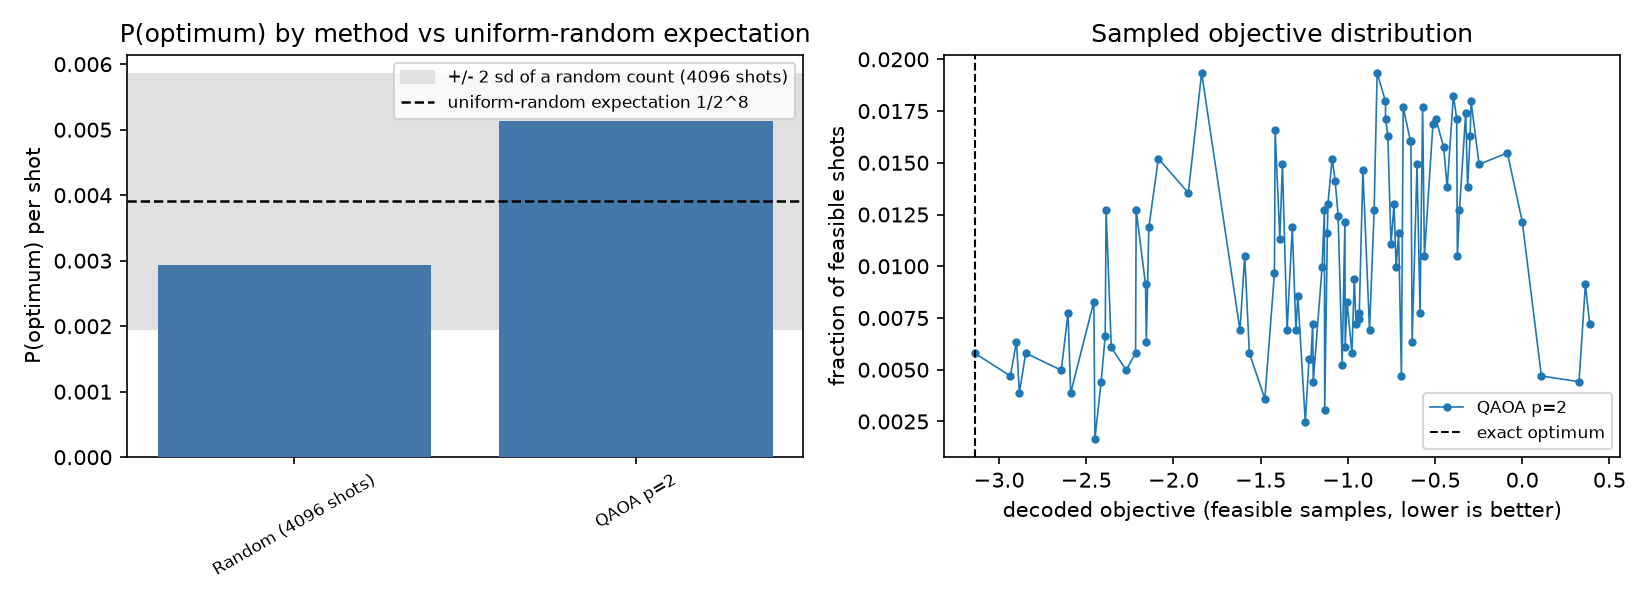

In [7]:
quick = False
matches_saved_demo = portfolio.seed == 0 and portfolio.n == 8 and qubo.lam == 0.3
if not matches_saved_demo:
    print("The model inputs changed. Tuning fresh angles with the reduced budget.")
runs, shots, source = select_qaoa_runs(
    qubo, quick=quick or not matches_saved_demo, results_dir=PROJECT / "results"
)
print("QAOA setup:", source.replace(str(PROJECT / "results"), "results"))
rows, histograms = build_rows(portfolio, qubo, shots, runs)
print(format_table(rows))

with TemporaryDirectory() as output_dir:
    plot_path = Path(output_dir) / "demo_plot.png"
    save_plot(rows, histograms, exact.objective, plot_path, portfolio.n, shots)
    display(Image(filename=str(plot_path)))

## 5. What we found

In our default demo, brute force, greedy, random sampling, and QAOA all reached a **0% best-portfolio gap**. QAOA sampled the optimum about **0.51%** of the time and the particular random run sampled it about **0.29%** of the time. Uniform random sampling over the 256 loan portfolios would hit this unique optimum about **0.39%** of the time on average.

In a reduced-budget run, QAOA can hit the optimum less often than random and still have a 0% gap. That is a valid experimental result. Check the hit rate as well as the best sample.

Across the team's larger set of experiments, QAOA results varied by seed and circuit depth. A single run's higher hit rate does not establish a consistent advantage. This instance is small enough for brute force to solve directly, and the team makes no quantum advantage claim. We also tested simulated noise and recorded two separate real IBM Quantum runs on smaller instances. Those two hardware runs gave mixed results against the random baseline.

The embedded experiment report has the full tables, including simulated annealing, decoded budget feasibility, multiple-testing correction, and the hardware comparisons. The project also explored how requiring at least one funded loan in every sector can change the best portfolio. That requirement is a separate experiment from the risk term used above.

## 6. Try it yourself

Change the risk weight while holding the loan book and budget fixed. Compare the selected loans, spend, expected return, and risk. The objective changes with the weight, so compare return and risk directly across rows.

Then try a different loan seed in section 1 and rerun sections 2–4 in order. Compare the new budget, exact solution, and sampler hit rates. Section 4 will tune new angles. To compare two seeds using the same tuning and shot budgets, set `quick = True` for both.

In [8]:
print(f"{'Risk weight':>11} {'Spend':>6} {'Return':>9} {'Risk':>9}  Funded loan IDs")
for weight in (0.0, 0.1, 0.3, 1.0):
    selection = brute_force(portfolio, lam=weight).x
    print(
        f"{weight:>11.1f} {int(portfolio.amount @ selection):>6}"
        f" {portfolio.ret @ selection:>9.4f}"
        f" {portfolio.portfolio_risk(selection):>9.4f}"
        f"  {np.flatnonzero(selection).tolist()}"
    )

Risk weight  Spend    Return      Risk  Funded loan IDs
        0.0     11    3.4540    1.0481  [1, 3, 5, 6]
        0.1     11    3.4540    1.0481  [1, 3, 5, 6]
        0.3     11    3.4540    1.0481  [1, 3, 5, 6]
        1.0     11    3.4540    1.0481  [1, 3, 5, 6]


## 7. Run the included CSV example

The notebook also carries a separate eight-loan CSV example with the columns `amount`, `expected_return`, and `sector`. The CSV solver applies its documented sector-correlation assumptions and prints a sector audit for the exact, greedy, and QAOA portfolios.

In [9]:
csv_path = PROJECT / "examples/loans_example.csv"
print(csv_path.read_text())

run_csv_solver = False
if run_csv_solver:
    result = subprocess.run(
        [sys.executable, "solve_csv.py", str(csv_path), "--budget", "12"],
        cwd=PROJECT, capture_output=True, text=True,
    )
    print(result.stdout + result.stderr)
    result.check_returncode()

amount,expected_return,sector
3,0.62,farming
5,1.10,farming
2,0.55,retail
4,0.80,retail
1,0.30,retail
6,1.45,services
2,0.40,services
7,1.20,farming



## 8. Run the full benchmark

Set `run_pipeline = True` to run the tests, risk-weight sweep, multi-seed QAOA, noise simulation, classical comparison, regenerated report, and independent verifier. A full run can take several minutes. It writes results only to the notebook's temporary workspace. The cell checks the pipeline summary because the runner can return exit code 0 after an optional step fails.

In [10]:
run_pipeline = False
if run_pipeline:
    completed = subprocess.run(
        [sys.executable, "scripts/run_all.py"],
        cwd=PROJECT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    print(completed.stdout)
    completed.check_returncode()
    if "Optional steps failed:" in completed.stdout or "SKIPPED (missing):" in completed.stdout:
        raise RuntimeError("The benchmark did not complete all steps. See the log above.")
else:
    print("Full benchmark is optional. The main walkthrough has already run.")

Full benchmark is optional. The main walkthrough has already run.


## 9. Follow-up experiments and recorded hardware

The bundled study varied the sector-coverage requirement, the budget encoding, the QAOA objective, the problem size, circuit angles, and the noise model. Each experiment below uses the same implementation as the original project. Some run several optimizations or circuit simulations and take longer than the main lesson.

The two recorded IBM Quantum experiments are available offline. This notebook also includes the project's hardware submission and retrieval code. A fresh hardware job requires an IBM Quantum account and is outside the offline exercises.

In [11]:
experiment = None  # Choose a name from the dictionary to rerun it.
experiments = {
    "fairness": [("scripts.impact_analysis",), ("scripts.price_of_fairness",)],
    "slack-free": [("qaoa_unbalanced",), ("scripts.unbalanced_min_decode",), ("scripts.unbalanced_holm",)],
    "cvar": [("qaoa_cvar",), ("scripts.cvar_holm",)],
    "scaling": [("scripts.scaling_study",)],
    "landscape": [("scripts.landscape",), ("scripts.spectrum_stats",)],
    "noise-mitigation": [("scripts.noise_ablation",)],
    "recorded-hardware-analysis": [("scripts.hardware_vs_random",), ("scripts.holm_correction",)],
}

if experiment is not None:
    for module, *args in experiments[experiment]:
        result = subprocess.run(
            [sys.executable, "-m", module, *args],
            cwd=PROJECT, capture_output=True, text=True,
        )
        print(result.stdout + result.stderr)
        result.check_returncode()
else:
    print("Optional experiments:", ", ".join(experiments))

print("Recorded hardware result files:")
for record in sorted((PROJECT / "results").glob("hardware_result*.json")):
    print(" ", record.name)

Optional experiments: fairness, slack-free, cvar, scaling, landscape, noise-mitigation, recorded-hardware-analysis
Recorded hardware result files:
  hardware_result.json
  hardware_result_seed1_n5_p1.json


In [12]:
from IPython.display import Markdown

show_report = False
if show_report:
    display(Markdown((PROJECT / "results/results.md").read_text()))

## Explore the embedded implementation

| Path | Role |
|---|---|
| `data.py`, `qubo.py` | Synthetic loan data, risk model, budget encoding, and Ising conversion |
| `baseline.py`, `sa_baseline.py` | Exact, greedy, random, and simulated-annealing baselines |
| `qaoa_run.py`, `demo.py`, `compare.py` | Circuit training, sampling, and comparisons |
| `solve_csv.py`, `examples/` | Example CSV input and portfolio solver |
| `noise_run.py`, `hardware_run.py` | Offline device-noise simulation and optional IBM Quantum submission |
| `tests/`, `scripts/run_all.py`, `results/` | Verification, main reproduction pipeline, and outputs |

In [13]:
source_file = "qubo.py"
show_source = False
if show_source:
    display(Code(filename=str(PROJECT / source_file), language="python"))
else:
    print("Set show_source = True to read the embedded implementation.")

Set show_source = True to read the embedded implementation.
